<a href="https://colab.research.google.com/github/KarthikSaravanakumarM56/24ADI006-24BAD056-DL/blob/main/DL_Lab09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#EXPERIMENT NO: 9
#TEXT CLASSIFICATION AND TEXT GENERATION USING TRANSFORMERS
PART A: DATASET PREPARATION AND TEXT PREPROCESSING

Roll No: 24BAD056
Name: M. Karthik Saravanakumar

1. LOADING IMDb DATASET


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

2. SAMPLE REVIEWS

Review: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h
Label: 0

Review: "I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity
Label: 0

Review: If only to avoid making this type of film in

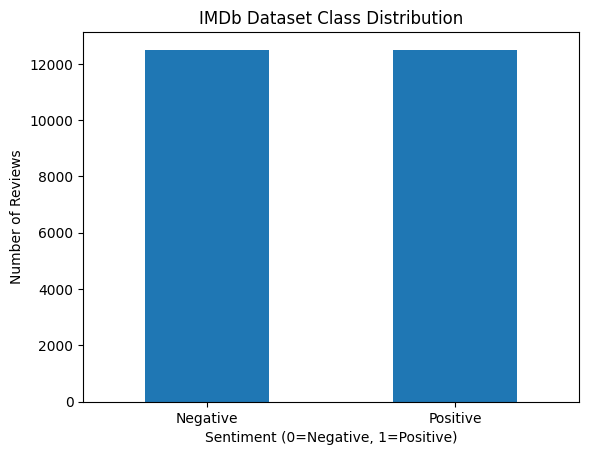


5. PREPARING TRAINING AND TESTING DATA
Training Samples: 2000
Testing Samples: 1000

6. LOADING BERT TOKENIZER


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT Tokenizer Loaded Successfully

7. TOKENIZATION AND PREPROCESSING


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]


8. TOKENIZED DATASET
Training Dataset: Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2000
})
Testing Dataset: Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1000
})

Sample Tokenized Data:
{'labels': 1, 'input_ids': [101, 2045, 2003, 2053, 7189, 2012, 2035, 2090, 3481, 3771, 1998, 6337, 2099, 2021, 1996, 2755, 2008, 2119, 2024, 2610, 2186, 2055, 6355, 6997, 1012, 6337, 2099, 3504, 15594, 2100, 1010, 3481, 3771, 3504, 4438, 1012, 6337, 2099, 14811, 2024, 3243, 3722, 1012, 3481, 3771, 1005, 1055, 5436, 2024, 2521, 2062, 8552, 1012, 1012, 1012, 3481, 3771, 3504, 2062, 2066, 3539, 8343, 1010, 2065, 2057, 2031, 2000, 3962, 12319, 1012, 1012, 1012, 1996, 2364, 2839, 2003, 5410, 1998, 6881, 2080, 1010, 2021, 2031, 1000, 17936, 6767, 7054, 3401, 1000, 1012, 2111, 2066, 2000, 12826, 1010, 2000, 3648, 1010, 2000, 16157, 1012, 2129, 2055, 2074, 9107, 1029, 6057, 2518, 2205, 1010, 2111, 3015, 

In [1]:
# Roll No: 24BAD056
# Name: M. Karthik Saravanakumar

!pip install -q transformers datasets accelerate scikit-learn

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding
print("Roll No: 24BAD056")
print("Name: M. Karthik Saravanakumar")

# 1. Load IMDb Dataset
print("\n1. LOADING IMDb DATASET")
dataset = load_dataset("stanfordnlp/imdb")
print(dataset)

# 2. Explore Sample Reviews and Labels
print("\n2. SAMPLE REVIEWS")
for i in range(3):
    print("\nReview:", dataset["train"][i]["text"][:300])
    print("Label:", dataset["train"][i]["label"])

# 3. Check Number of Samples
print("\n3. DATASET INFORMATION")
print("Total Training Samples:", len(dataset["train"]))
print("Total Testing Samples:", len(dataset["test"]))

# 4. Class Distribution
print("\n4. CLASS DISTRIBUTION")
labels = dataset["train"]["label"]
label_counts = pd.Series(labels).value_counts().sort_index()
print("Negative Reviews (0):", label_counts[0])
print("Positive Reviews (1):", label_counts[1])
label_counts.plot(kind="bar")
plt.title("IMDb Dataset Class Distribution")
plt.xlabel("Sentiment (0=Negative, 1=Positive)")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1], ["Negative", "Positive"], rotation=0)
plt.show()

# 5. Separate Training and Testing Data
print("\n5. PREPARING TRAINING AND TESTING DATA")
train_data = dataset["train"].shuffle(seed=42).select(range(2000))
test_data = dataset["test"].shuffle(seed=42).select(range(1000))
print("Training Samples:", len(train_data))
print("Testing Samples:", len(test_data))

# 6. Load Pretrained BERT Tokenizer
print("\n6. LOADING BERT TOKENIZER")
model_name = "google-bert/bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
print("BERT Tokenizer Loaded Successfully")

# 7. Tokenization
print("\n7. TOKENIZATION AND PREPROCESSING")
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=256,
        padding=False
    )
tokenized_train = train_data.map(
    tokenize_function,
    batched=True
)
tokenized_test = test_data.map(
    tokenize_function,
    batched=True
)

# 8. Prepare Dataset for Training
tokenized_train = tokenized_train.remove_columns(["text"])
tokenized_test = tokenized_test.remove_columns(["text"])
tokenized_train = tokenized_train.rename_column(
    "label", "labels"
)
tokenized_test = tokenized_test.rename_column(
    "label", "labels"
)

# 9. Dynamic Padding and Batch Processing
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)
print("\n8. TOKENIZED DATASET")
print("Training Dataset:", tokenized_train)
print("Testing Dataset:", tokenized_test)
print("\nSample Tokenized Data:")
print(tokenized_train[0])
print("\nInput IDs:", tokenized_train[0]["input_ids"][:15])
print("Attention Mask:", tokenized_train[0]["attention_mask"][:15])
print("\nPART A COMPLETED SUCCESSFULLY!")

PART B: FINE-TUNING BERT FOR TEXT CLASSIFICATION

In [2]:
# Roll No: 24BAD056
# Name: M. Karthik Saravanakumar

from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np
import torch
print("PART B: BERT TEXT CLASSIFICATION")

# 1. Load Pretrained BERT Model
print("\n1. LOADING BERT MODEL")
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)
print("BERT Model Loaded Successfully")

# 2. Define Evaluation Metrics
print("\n2. DEFINING EVALUATION METRICS")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            labels, predictions, zero_division=0
        )
    }
print("Evaluation Metrics Defined")

# 3. Configure Training Parameters
print("\n3. CONFIGURING TRAINING PARAMETERS")
training_args = TrainingArguments(
    output_dir="./bert_results",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    report_to="none",
    fp16=torch.cuda.is_available()
)
print("Learning Rate: 2e-5")
print("Batch Size: 8")
print("Epochs: 1")

# 4. Initialize Trainer
print("\n4. INITIALIZING TRAINER")
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)
print("Trainer Initialized Successfully")

# 5. Fine-Tune BERT Model
print("\n5. STARTING BERT TRAINING")
trainer.train()
print("BERT Fine-Tuning Completed Successfully")

# 6. Evaluate Model
print("\n6. MODEL EVALUATION")
results = trainer.evaluate()
print("\nCLASSIFICATION PERFORMANCE")
print("Accuracy:", round(results["eval_accuracy"], 4))
print("Precision:", round(results["eval_precision"], 4))
print("Recall:", round(results["eval_recall"], 4))
print("F1 Score:", round(results["eval_f1"], 4))

# 7. Test New Text Inputs
print("\n7. TESTING NEW MOVIE REVIEWS")
reviews = [
    "This movie was amazing and the acting was excellent!",
    "The movie was boring and completely disappointing.",
    "I really enjoyed this film. It was wonderful.",
    "The story was terrible and the movie was a waste of time."
]
model.eval()
for review in reviews:
    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    ).to(model.device)
    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(
            outputs.logits, dim=1
        )
        prediction = torch.argmax(
            probabilities, dim=1
        ).item()
    sentiment = "Positive" if prediction == 1 else "Negative"
    print("\nReview:", review)
    print("Predicted Sentiment:", sentiment)
    print("Confidence:",
          round(probabilities[0][prediction].item(), 4))

# 8. Save Fine-Tuned Model and Tokenizer
print("\n8. SAVING BERT MODEL")
model.save_pretrained("./saved_bert_model")
tokenizer.save_pretrained("./saved_bert_model")
print("BERT Model Saved Successfully")
print("\nPART B COMPLETED SUCCESSFULLY!")

PART B: BERT TEXT CLASSIFICATION

1. LOADING BERT MODEL


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT Model Loaded Successfully

2. DEFINING EVALUATION METRICS
Evaluation Metrics Defined

3. CONFIGURING TRAINING PARAMETERS
Learning Rate: 2e-5
Batch Size: 8
Epochs: 1

4. INITIALIZING TRAINER
Trainer Initialized Successfully

5. STARTING BERT TRAINING


... (2 outputs left out)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.298824,0.311064,1,0.870000,0.850980,0.889344,0.869739



CLASSIFICATION PERFORMANCE
Accuracy: 0.87
Precision: 0.851
Recall: 0.8893
F1 Score: 0.8697

7. TESTING NEW MOVIE REVIEWS

Review: This movie was amazing and the acting was excellent!
Predicted Sentiment: Positive
Confidence: 0.9544

Review: The movie was boring and completely disappointing.
Predicted Sentiment: Negative
Confidence: 0.9558

Review: I really enjoyed this film. It was wonderful.
Predicted Sentiment: Positive
Confidence: 0.9502

Review: The story was terrible and the movie was a waste of time.
Predicted Sentiment: Negative
Confidence: 0.9574

8. SAVING BERT MODEL


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT Model Saved Successfully

PART B COMPLETED SUCCESSFULLY!


PART C: IMPLEMENTING A SEQUENCE-TO-SEQUENCE APPLICATION USING TRANSFORMERS

In [3]:
# Roll No: 24BAD056
# Name: M. Karthik Saravanakumar

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)
import torch
import pandas as pd
print("PART C: TEXT GENERATION USING T5")

# 1. Load T5-small Model
print("\n1. LOADING T5-SMALL MODEL")
t5_model_name = "google-t5/t5-small"
t5_tokenizer = AutoTokenizer.from_pretrained(
    t5_model_name
)
t5_model = AutoModelForSeq2SeqLM.from_pretrained(
    t5_model_name
)
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
t5_model = t5_model.to(device)
print("T5-small Model Loaded Successfully")

# 2. Prepare Sample Input
print("\n2. PREPARING INPUT TEXT")
input_text = """
Artificial Intelligence is transforming the education system.
It helps students learn through personalized learning methods.
Teachers can use AI to identify student weaknesses and provide
appropriate learning materials. AI also supports automatic
assessment and improves the overall learning experience.
"""
print("Original Input Text:")
print(input_text)

# 3. Preprocess Input Text
print("\n3. TOKENIZATION")
text = "summarize: " + input_text
inputs = t5_tokenizer(
    text,
    return_tensors="pt",
    max_length=512,
    truncation=True
).to(device)
print("Input Tokenization Completed")
print("Input IDs:", inputs["input_ids"])

# 4. Generate Text
print("\n4. GENERATING SUMMARY")
with torch.no_grad():
    output = t5_model.generate(
        **inputs,
        max_length=100,
        min_length=20,
        num_beams=4,
        early_stopping=True
    )
generated_text = t5_tokenizer.decode(
    output[0],
    skip_special_tokens=True
)
print("\nOriginal Text:")
print(input_text)
print("\nGenerated Summary:")
print(generated_text)

# 5. Experiment with Different Input Texts
print("\n5. TESTING DIFFERENT INPUTS")
texts = [
    "Artificial Intelligence helps computers perform tasks "
    "that normally require human intelligence. It is used in "
    "healthcare, education and transportation.",
    "Cloud computing provides computing services over the internet. "
    "It allows users to store data, run applications and access "
    "resources without maintaining physical servers.",
    "Machine Learning is a branch of Artificial Intelligence. "
    "It allows systems to learn from data and improve their "
    "performance without being explicitly programmed."
]
generated_outputs = []
for i, paragraph in enumerate(texts):
    inputs = t5_tokenizer(
        "summarize: " + paragraph,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)
    with torch.no_grad():
        output = t5_model.generate(
            **inputs,
            max_length=80,
            num_beams=4
        )
    summary = t5_tokenizer.decode(
        output[0],
        skip_special_tokens=True
    )
    generated_outputs.append({
        "Input Text": paragraph,
        "Generated Summary": summary
    })
    print("\nInput", i+1, ":")
    print(paragraph)
    print("\nGenerated Summary:")
    print(summary)

# 6. Experiment with Different Generation Settings
print("\n6. COMPARING GENERATION PARAMETERS")
sample = "summarize: " + input_text
inputs = t5_tokenizer(
    sample,
    return_tensors="pt",
    truncation=True,
    max_length=512
).to(device)
with torch.no_grad():
    output1 = t5_model.generate(
        **inputs,
        max_length=80,
        num_beams=2
    )
    output2 = t5_model.generate(
        **inputs,
        max_length=120,
        num_beams=5
    )
summary1 = t5_tokenizer.decode(
    output1[0],
    skip_special_tokens=True
)
summary2 = t5_tokenizer.decode(
    output2[0],
    skip_special_tokens=True
)
print("\nGeneration with 2 Beams:")
print(summary1)
print("\nGeneration with 5 Beams:")
print(summary2)

# 7. Analyze Generated Text Quality
print("\n7. TEXT GENERATION QUALITY ANALYSIS")
for i, item in enumerate(generated_outputs):
    summary = item["Generated Summary"]
    print("\nSample:", i+1)
    print("Generated Summary:", summary)
    print("Generated Word Count:",
          len(summary.split()))
    if len(summary.strip()) > 0:
        print("Status: Output Generated Successfully")
    else:
        print("Status: Empty Output")

# 8. Save Generated Outputs
print("\n8. SAVING GENERATED OUTPUTS")
df = pd.DataFrame(generated_outputs)
df.to_csv(
    "generated_summaries.csv",
    index=False
)
print(df)
print("\nGenerated Outputs Saved as generated_summaries.csv")
print("\nPART C COMPLETED SUCCESSFULLY!")

PART C: TEXT GENERATION USING T5

1. LOADING T5-SMALL MODEL


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5-small Model Loaded Successfully

2. PREPARING INPUT TEXT
Original Input Text:

Artificial Intelligence is transforming the education system.
It helps students learn through personalized learning methods.
Teachers can use AI to identify student weaknesses and provide
appropriate learning materials. AI also supports automatic
assessment and improves the overall learning experience.


3. TOKENIZATION
Input Tokenization Completed
Input IDs: tensor([[21603,    10, 24714,  5869,  2825,  1433,    19,     3, 21139,     8,
          1073,   358,     5,    94,  1691,   481,   669,   190,  9354,  1036,
          2254,     5, 18991,    54,   169,  7833,    12,  2862,  1236, 21506,
            11,   370,  2016,  1036,  1397,     5,  7833,    92,  4951,  6569,
          4193,    11,  1172,     7,     8,  1879,  1036,   351,     5,     1]],
       device='cuda:0')

4. GENERATING SUMMARY

Original Text:

Artificial Intelligence is transforming the education system.
It helps students learn through p

PART D: MODEL TESTING AND OUTPUT ANALYSIS

PART D: MODEL TESTING AND OUTPUT ANALYSIS

1. TESTING BERT CLASSIFICATION
                                           Review Predicted Sentiment  Confidence
The movie was fantastic and I loved every moment.            Positive      0.9230
    The film was very boring and poorly directed.            Negative      0.9463
        Excellent acting and wonderful storyline.            Positive      0.9201
                 Worst movie I have ever watched.            Negative      0.9097

2. CLASSIFICATION REPORT


              precision    recall  f1-score   support

    Negative       0.89      0.85      0.87       512
    Positive       0.85      0.89      0.87       488

    accuracy                           0.87      1000
   macro avg       0.87      0.87      0.87      1000
weighted avg       0.87      0.87      0.87      1000


3. CONFUSION MATRIX


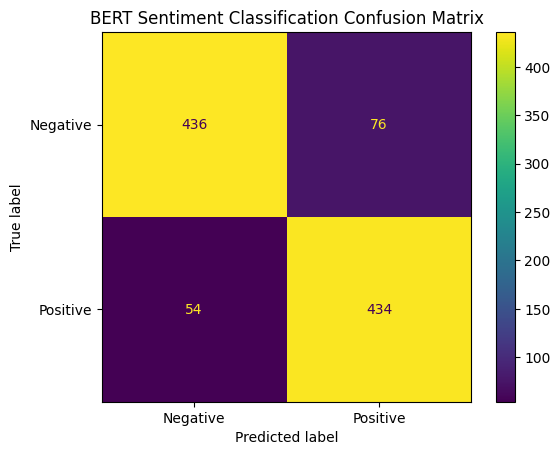


4. TEXT GENERATION OUTPUT ANALYSIS

Sample: 1
Original Text:
Artificial Intelligence helps computers perform tasks that normally require human intelligence. It is used in healthcare, education and transportation.

Generated Summary:
artificial intelligence helps computers perform tasks that normally require human intelligence. it is used in healthcare, education and transportation.

Original Word Count: 19
Summary Word Count: 19
Readability Check: Non-empty text generated
Relevance: Manually verify whether the summary preserves the main idea.

Sample: 2
Original Text:
Cloud computing provides computing services over the internet. It allows users to store data, run applications and access resources without maintaining physical servers.

Generated Summary:
cloud computing provides computing services over the internet. it allows users to store data, run applications and access resources without maintaining physical servers.

Original Word Count: 23
Summary Word Count: 23
Readability Chec

In [4]:
# Roll No: 24BAD056
# Name: M. Karthik Saravanakumar

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
print("PART D: MODEL TESTING AND OUTPUT ANALYSIS")

# 1. Test BERT with Positive and Negative Reviews
print("\n1. TESTING BERT CLASSIFICATION")
test_reviews = [
    "The movie was fantastic and I loved every moment.",
    "The film was very boring and poorly directed.",
    "Excellent acting and wonderful storyline.",
    "Worst movie I have ever watched."
]
bert_results = []
model.eval()
for review in test_reviews:
    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    ).to(model.device)
    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(
            outputs.logits, dim=1
        )
        prediction = torch.argmax(
            probabilities, dim=1
        ).item()
    sentiment = "Positive" if prediction == 1 else "Negative"
    bert_results.append({
        "Review": review,
        "Predicted Sentiment": sentiment,
        "Confidence": round(
            probabilities[0][prediction].item(), 4
        )
    })
bert_df = pd.DataFrame(bert_results)
print(bert_df.to_string(index=False))

# 2. Classification Report
print("\n2. CLASSIFICATION REPORT")
predictions = trainer.predict(tokenized_test)
y_pred = np.argmax(
    predictions.predictions,
    axis=1
)
y_true = predictions.label_ids
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)

# 3. Confusion Matrix
print("\n3. CONFUSION MATRIX")
cm = confusion_matrix(
    y_true,
    y_pred
)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)
display.plot()
plt.title("BERT Sentiment Classification Confusion Matrix")
plt.show()

# 4. Analyze T5 Generated Outputs
print("\n4. TEXT GENERATION OUTPUT ANALYSIS")
for i, row in df.iterrows():
    original = row["Input Text"]
    summary = row["Generated Summary"]
    print("\nSample:", i+1)
    print("Original Text:")
    print(original)
    print("\nGenerated Summary:")
    print(summary)
    print("\nOriginal Word Count:",
          len(original.split()))
    print("Summary Word Count:",
          len(summary.split()))
    if summary.strip():
        print("Readability Check: Non-empty text generated")
        print("Relevance: Manually verify whether the "
              "summary preserves the main idea.")
    else:
        print("Readability Check: Empty output")

# 5. Compare BERT and T5
print("\n5. COMPARISON OF BERT AND T5")
comparison = pd.DataFrame({
    "Feature": [
        "Model",
        "Architecture",
        "Purpose",
        "Input",
        "Output",
        "Application"
    ],
    "BERT": [
        "BERT Base Uncased",
        "Encoder",
        "Text Classification",
        "Movie Review",
        "Positive / Negative",
        "Sentiment Analysis"
    ],
    "T5": [
        "T5-small",
        "Encoder-Decoder",
        "Text Generation",
        "Paragraph",
        "Generated Summary",
        "Text Summarization"
    ]
})
print(comparison.to_string(index=False))

# 6. Identify Model Limitations
print("\n6. MODEL LIMITATIONS")

print("1. BERT requires labelled training data.")

print("2. BERT may misclassify complex or sarcastic reviews.")

print("3. T5 may generate incomplete summaries.")

print("4. T5 may sometimes miss important information.")

print("5. Model performance depends on dataset quality.")

print("6. Generated summaries should be checked for relevance.")

# 7. Final Observations
print("\n7. FINAL OBSERVATIONS")

print("1. BERT successfully performs sentiment classification.")

print("2. Positive and negative reviews are classified.")

print("3. Accuracy, Precision, Recall and F1-score are used "
      "for evaluation.")

print("4. T5 generates summaries from input paragraphs.")

print("5. Different beam search settings produce different "
      "generation results.")

print("6. BERT is suitable for classification tasks.")

print("7. T5 is suitable for sequence-to-sequence generation tasks.")

print("\nEXPERIMENT NO: 9 COMPLETED SUCCESSFULLY!")